# LEP-16 : Analyse de l'évolution temporelle de l'espérance de vie (2000–2015)

**Projet :** WHO Life Expectancy, Analyse des facteurs associés à l'espérance de vie  
**Sprint :** Sprint 3, Analyse exploratoire et comparative  
**User Story :** LEP-16  
**Environnement :** Python, Jupyter Notebook  
**Source des données :** Jeu de données fiabilisé (`data/processed/life_expectancy_fiabilise.csv`)

---

## 1. Contexte et objectif

Dans le cadre du projet WHO Life Expectancy, cette analyse vise à étudier l'évolution de l'espérance de vie entre 2000 et 2015, à partir des données nationales harmonisées avec celles de la Banque mondiale.

Après avoir identifié les pays présentant les valeurs les plus élevées et les plus faibles (LEP-14), puis comparé les pays selon leur statut de développement (LEP-15), cette User Story s'intéresse à la dimension temporelle des disparités internationales.

### Question analytique

**Comment l'espérance de vie a-t-elle évolué entre 2000 et 2015, et dans quelle mesure cette évolution diffère-t-elle selon les pays ?**

### Objectifs spécifiques

- Décrire l'évolution annuelle des indicateurs centraux d'espérance de vie.
- Mesurer les variations nationales entre 2000 et 2015.
- Identifier les pays ayant enregistré les progressions et les reculs les plus importants.
- Examiner l'évolution de la dispersion des espérances de vie entre pays.
- Synthétiser les principales tendances et leurs limites.

### Périmètre méthodologique

L'analyse porte sur les années 2000 à 2015 et utilise les valeurs de l'indicateur `SP.DYN.LE00.IN` de la Banque mondiale, intégrées au jeu de données fiabilisé.

Afin de maintenir une couverture géographique constante, les comparaisons temporelles seront réalisées sur un panel commun de pays disposant d'observations pour l'ensemble des 16 années.

Les statistiques descriptives seront calculées sans pondération par la population. Les variations observées ne seront pas interprétées comme des relations causales.

## 5.1. Charger les données

In [1]:
# Bibliotheques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

# Charger le jeu de données fiabilisé
df = pd.read_csv("../data/processed/life_expectancy_fiabilise.csv")

# Sélectionner les variables nécessaires
df_lep16 = df[
    ["country", "year", "life_expectancy"]
].copy()

# Vérifier les dimensions et la couverture temporelle
print("Dimensions :", df_lep16.shape)
print("Nombre de pays :", df_lep16["country"].nunique())
print("Période :", df_lep16["year"].min(), "-", df_lep16["year"].max())

display(df_lep16.head())


Dimensions : (2938, 3)
Nombre de pays : 193
Période : 2000 - 2015


,country,year,life_expectancy
0,Afghanistan,2015,62.270
1,Afghanistan,2014,62.260
2,Afghanistan,2013,62.188
3,Afghanistan,2012,61.735
4,Afghanistan,2011,61.250


## 5.2.  Constitution du panel temporel équilibré

Nous devons constituer un panel équilibré, c'est-à-dire retenir les mêmes pays pour toutes les années de 2000 à 2015.

In [3]:

# Définir la période étudiée
annees_attendues = set(range(2000, 2016))

# Identifier les années disponibles pour chaque pays
couverture = (
    df_lep16.groupby("country")["year"]
    .agg(lambda x: set(x))
)

# Retenir les pays présents sur les 16 années
pays_communs = couverture[
    couverture.apply(lambda x: annees_attendues.issubset(x))
].index

# Construire le panel temporel
df_panel = df_lep16[
    df_lep16["country"].isin(pays_communs)
].copy()

# Vérifier le résultat
print("Nombre de pays retenus :", df_panel["country"].nunique())
print("Dimensions du panel :", df_panel.shape)

print("\nObservations par année :")
display(df_panel.groupby("year").size())

print("\nValeurs manquantes :")
display(df_panel.isna().sum())

print("\nDoublons pays-année :",
      df_panel.duplicated(subset=["country", "year"]).sum())


Nombre de pays retenus : 183
Dimensions du panel : (2928, 3)

Observations par année :


year
2000    183
2001    183
2002    183
2003    183
2004    183
2005    183
2006    183
2007    183
2008    183
2009    183
2010    183
2011    183
2012    183
2013    183
2014    183
2015    183
dtype: int64


Valeurs manquantes :


country            0
year               0
life_expectancy    0
dtype: int64


Doublons pays-année : 0


**Constat :** Le jeu de données initial contient 2 938 observations correspondant à 193 pays sur la période 2000–2015. Après vérification de la couverture temporelle, 183 pays disposent d'observations pour chacune des 16 années étudiées.

Le panel équilibré ainsi constitué comprend 2 928 observations, avec exactement 183 pays représentés chaque année. Les dix autres pays ne disposent pas d'une couverture temporelle complète et sont exclus des comparaisons longitudinales.

La constitution d'un panel équilibré permet de comparer l'évolution de l'espérance de vie sur une base géographique constante. Les variations des statistiques annuelles ne résulteront donc pas de changements dans la composition des pays étudiés.

**Décision :** Retenir les 183 pays du panel équilibré pour l'ensemble des analyses temporelles de LEP-16, afin de garantir la comparabilité des résultats entre 2000 et 2015.

## 5.3. Évolution globale de l'espérance de vie

### 5.3.1 Calcul des indicateurs annuels

In [4]:

# Calculer les indicateurs descriptifs pour chaque année
evolution_globale = (
    df_panel.groupby("year")["life_expectancy"]
    .agg(
        moyenne="mean",
        mediane="median",
        ecart_type="std",
        minimum="min",
        maximum="max"
    )
    .round(2)
)

# Calculer l'écart entre les valeurs extrêmes
evolution_globale["etendue"] = (
    evolution_globale["maximum"]
    - evolution_globale["minimum"]
).round(2)

# Afficher le tableau
display(evolution_globale)


,moyenne,mediane,ecart_type,minimum,maximum,etendue
year,,,,,,
2000,66.40,69.58,9.75,44.83,81.08,36.25
2001,66.74,69.80,9.74,44.52,81.42,36.90
2002,67.03,70.03,9.65,45.38,81.69,36.31
2003,67.38,70.23,9.53,44.63,81.76,37.13
2004,67.72,70.43,9.47,43.91,82.03,38.12
2005,68.08,70.56,9.35,43.61,81.96,38.35
2006,68.43,70.87,9.20,43.18,82.32,39.14
2007,68.78,70.90,9.05,43.66,82.51,38.85
2008,69.11,71.12,8.93,44.30,82.59,38.29


**Constat :** Sur le panel équilibré de 183 pays, l'espérance de vie moyenne progresse de manière continue entre 2000 et 2015, passant de 66,40 à 71,20 ans, soit une augmentation de 4,80 ans.

La médiane suit également une tendance générale à la hausse, passant de 69,58 à 72,82 ans, malgré quelques fluctuations ponctuelles.

Parallèlement, l'écart-type diminue de 9,75 à 8,26 ans, ce qui indique une réduction globale de la dispersion des espérances de vie entre les pays.

En revanche, l'étendue augmente de 36,25 ans en 2000 à 44,03 ans en 2015. Elle présente des variations particulièrement importantes en 2009 (68,27 ans) et en 2011 (50,25 ans), associées à des valeurs minimales exceptionnellement faibles.

Ces résultats suggèrent une amélioration générale de l'espérance de vie et un rapprochement progressif des niveaux nationaux sur la période étudiée.

Toutefois, la diminution de l'écart-type ne signifie pas que toutes les disparités ont disparu. L'augmentation de l'étendue et la présence de valeurs atypiques montrent que certains pays continuent de présenter des situations particulièrement défavorables.

L'évolution de l'espérance de vie apparaît donc globalement favorable, mais elle reste hétérogène selon les pays.

### 5.3.2. Visualisation de l'évolution globale

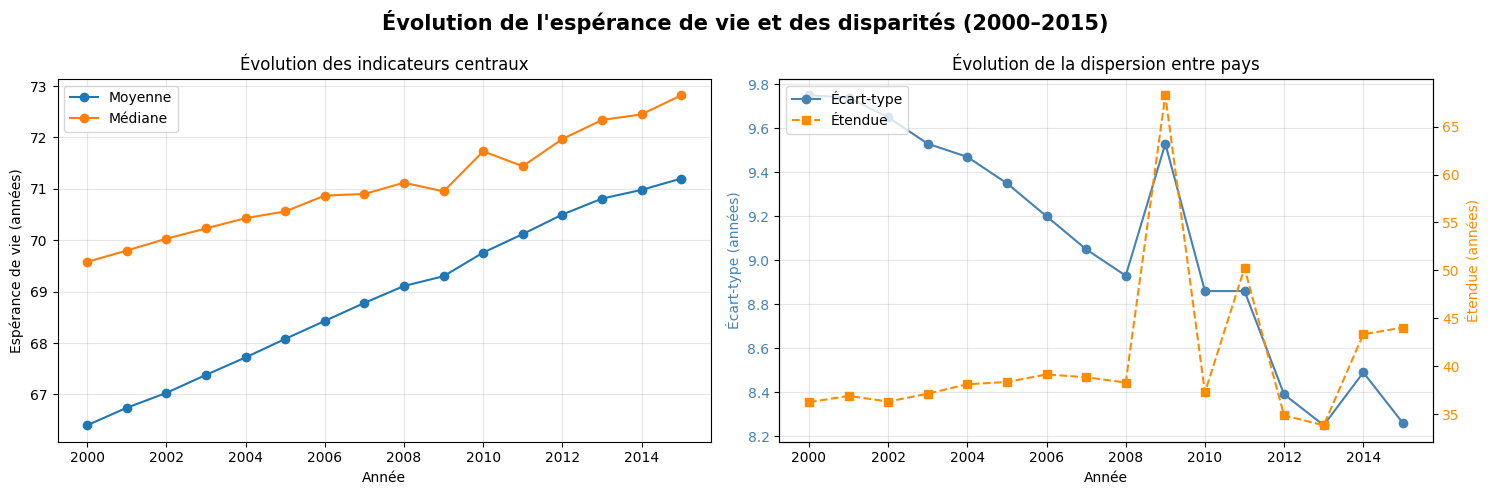

In [5]:

# Créer deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graphique 1 : moyenne et médiane
axes[0].plot(
    evolution_globale.index,
    evolution_globale["moyenne"],
    marker="o",
    label="Moyenne"
)

axes[0].plot(
    evolution_globale.index,
    evolution_globale["mediane"],
    marker="o",
    label="Médiane"
)

axes[0].set_title("Évolution des indicateurs centraux")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("Espérance de vie (années)")
axes[0].set_xticks(range(2000, 2016, 2))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Graphique 2 : écart-type
ax1 = axes[1]

ligne1 = ax1.plot(
    evolution_globale.index,
    evolution_globale["ecart_type"],
    marker="o",
    color="steelblue",
    label="Écart-type"
)

ax1.set_xlabel("Année")
ax1.set_ylabel("Écart-type (années)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.set_xticks(range(2000, 2016, 2))
ax1.grid(alpha=0.3)

# Deuxième axe : étendue
ax2 = ax1.twinx()

ligne2 = ax2.plot(
    evolution_globale.index,
    evolution_globale["etendue"],
    marker="s",
    linestyle="--",
    color="darkorange",
    label="Étendue"
)

ax2.set_ylabel("Étendue (années)", color="darkorange")
ax2.tick_params(axis="y", labelcolor="darkorange")

ax1.set_title("Évolution de la dispersion entre pays")

# Légende commune au graphique de droite
lignes = ligne1 + ligne2
ax1.legend(
    lignes,
    [ligne.get_label() for ligne in lignes],
    loc="upper left"
)

# Titre général
fig.suptitle(
    "Évolution de l'espérance de vie et des disparités (2000–2015)",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Constat :** Le premier graphique met en évidence une progression générale des indicateurs centraux de l'espérance de vie entre 2000 et 2015. La moyenne augmente de 66,40 à 71,20 ans, tandis que la médiane passe de 69,58 à 72,82 ans.

La moyenne demeure inférieure à la médiane sur l'ensemble de la période, mais l'écart entre ces deux indicateurs se réduit progressivement, passant de 3,18 à 1,62 an.

Le second graphique montre une diminution globale de l'écart-type, qui passe de 9,75 à 8,26 ans. L'étendue présente cependant une évolution plus irrégulière, avec des pics particulièrement marqués en 2009 et en 2011, associés à des observations exceptionnellement faibles.

Les résultats suggèrent une amélioration générale de l'espérance de vie et une réduction de la dispersion des niveaux nationaux entre 2000 et 2015.

Toutefois, cette évolution favorable ne concerne pas nécessairement tous les pays de manière uniforme. Les variations importantes de l'étendue montrent que certaines situations nationales restent particulièrement éloignées du reste de la distribution.

Ainsi, l'amélioration des indicateurs centraux et la réduction de la dispersion globale peuvent coexister avec la persistance de valeurs extrêmes importantes.

## 5.4 Évolution de l'espérance de vie par pays

### 5.4.1. Calcul des variations nationales entre 2000 et 2015

In [6]:

# Sélectionner les observations des années 2000 et 2015
df_extremites = df_panel[
    df_panel["year"].isin([2000, 2015])
].copy()

# Réorganiser les données : une ligne par pays
evolution_pays = (
    df_extremites
    .pivot(
        index="country",
        columns="year",
        values="life_expectancy"
    )
    .rename(columns={
        2000: "esperance_2000",
        2015: "esperance_2015"
    })
)

# Calculer la variation de l'espérance de vie
evolution_pays["variation"] = (
    evolution_pays["esperance_2015"]
    - evolution_pays["esperance_2000"]
)

# Calculer le taux de variation en pourcentage
evolution_pays["variation_pct"] = (
    evolution_pays["variation"]
    / evolution_pays["esperance_2000"]
    * 100
)

# Afficher les premières observations
display(evolution_pays.round(2).head())

# Vérifier le nombre de pays
print("Nombre de pays :", len(evolution_pays))

# Résumer les variations
display(evolution_pays["variation"].describe().round(2))


year,esperance_2000,esperance_2015,variation,variation_pct
country,,,,
Afghanistan,55.00,62.27,7.26,13.21
Albania,74.83,78.36,3.53,4.72
Algeria,70.58,75.16,4.58,6.49
Angola,46.50,61.04,14.54,31.27
Antigua and Barbuda,74.82,76.89,2.07,2.77


Nombre de pays : 183


count    183.00
mean       4.80
std        3.33
min       -7.83
25%        2.84
50%        4.31
75%        6.10
max       17.62
Name: variation, dtype: float64

**Constat :** Sur les 183 pays du panel équilibré, la variation moyenne de l'espérance de vie entre 2000 et 2015 est de +4,80 ans, tandis que la variation médiane atteint +4,31 ans.

La moitié centrale des pays présente des variations comprises entre +2,84 et +6,10 ans, avec un écart-type global des variations de 3,33 ans.

Les valeurs extrêmes mettent cependant en évidence des trajectoires contrastées : la progression maximale atteint +17,62 ans, tandis que la variation minimale est de −7,83 ans.

Ces résultats confirment une amélioration générale de l'espérance de vie entre les deux années de référence, mais montrent également que cette évolution est inégale selon les pays.

La dispersion des variations nationales souligne l'importance de compléter l'analyse globale par l'identification des pays ayant enregistré les progressions les plus fortes et les reculs les plus importants.

Il convient toutefois de préciser que ces variations sont calculées entre les valeurs de 2000 et de 2015. Elles ne décrivent donc pas les fluctuations intermédiaires qui ont pu survenir au cours de la période.

### 5.4.2. Identification des progressions et des reculs les plus importants

In [7]:

# Identifier les 10 plus fortes progressions
top_progressions = (
    evolution_pays
    .sort_values("variation", ascending=False)
    .head(10)
)

# Identifier les 10 variations les plus faibles
bottom_progressions = (
    evolution_pays
    .sort_values("variation", ascending=True)
    .head(10)
)

print("TOP 10 — Plus fortes progressions")
display(top_progressions.round(2))

print("\nBOTTOM 10 — Variations les plus faibles")
display(bottom_progressions.round(2))

# Compter les pays selon le sens de leur évolution
bilan_variations = pd.Series({
    "Progression": (evolution_pays["variation"] > 0).sum(),
    "Stabilité": (evolution_pays["variation"] == 0).sum(),
    "Recul": (evolution_pays["variation"] < 0).sum()
})

print("\nRépartition des pays selon leur évolution")
display(bilan_variations)


TOP 10 — Plus fortes progressions


year,esperance_2000,esperance_2015,variation,variation_pct
country,,,,
Rwanda,47.80,65.42,17.62,36.87
Malawi,46.17,62.32,16.15,34.99
Angola,46.50,61.04,14.54,31.27
Uganda,49.64,63.83,14.19,28.59
Zambia,46.58,60.73,14.15,30.38
Zimbabwe,46.03,58.99,12.95,28.14
Ethiopia,50.88,63.59,12.71,24.98
Burundi,47.62,60.11,12.49,26.23
Democratic People's Republic of Korea,60.91,72.82,11.91,19.56



BOTTOM 10 — Variations les plus faibles


year,esperance_2000,esperance_2015,variation,variation_pct
country,,,,
South Sudan,47.59,39.76,-7.83,-16.46
Syrian Arab Republic,70.86,63.26,-7.59,-10.71
Saint Vincent and the Grenadines,70.35,70.46,0.11,0.16
Samoa,70.79,71.06,0.27,0.38
Fiji,66.19,66.48,0.29,0.43
Venezuela (Bolivarian Republic of),72.39,73.00,0.62,0.85
Brunei Darussalam,74.02,74.88,0.86,1.17
Jamaica,71.28,72.21,0.93,1.31
Micronesia (Federated States of),64.32,65.31,0.99,1.54



Répartition des pays selon leur évolution


Progression    181
Stabilité        0
Recul            2
dtype: int64

**Constat :** Sur les 183 pays étudiés, 181 enregistrent une augmentation de leur espérance de vie entre 2000 et 2015, soit 98,91 % du panel. Seuls deux pays présentent un recul, et aucun ne conserve exactement la même valeur.

Les progressions les plus importantes sont observées au Rwanda (+17,62 ans), au Malawi (+16,15 ans) et en Angola (+14,54 ans). Neuf des dix pays ayant enregistré les gains les plus élevés se situent en Afrique.

À l'inverse, le Soudan du Sud (−7,83 ans) et la Syrie (−7,59 ans) sont les deux seuls pays dont l'espérance de vie diminue entre les deux années de référence.

Les huit autres pays figurant parmi les dix variations les plus faibles présentent des gains positifs, mais limités, compris entre +0,11 et +1,10 an.

Les résultats confirment que l'amélioration de l'espérance de vie entre 2000 et 2015 concerne la très grande majorité des pays étudiés.

Toutefois, l'ampleur des gains varie considérablement d'un pays à l'autre. Les fortes progressions observées dans plusieurs pays initialement caractérisés par une espérance de vie relativement faible suggèrent un certain rapprochement des niveaux nationaux.

Les reculs observés au Soudan du Sud et en Syrie montrent néanmoins que cette amélioration n'est pas universelle.

Enfin, ces résultats reposent sur la comparaison de deux années, 2000 et 2015. Ils ne permettent pas de déterminer si les évolutions nationales ont été régulières pendant la période intermédiaire.

### 5.4.3. Visualisation des variations nationales

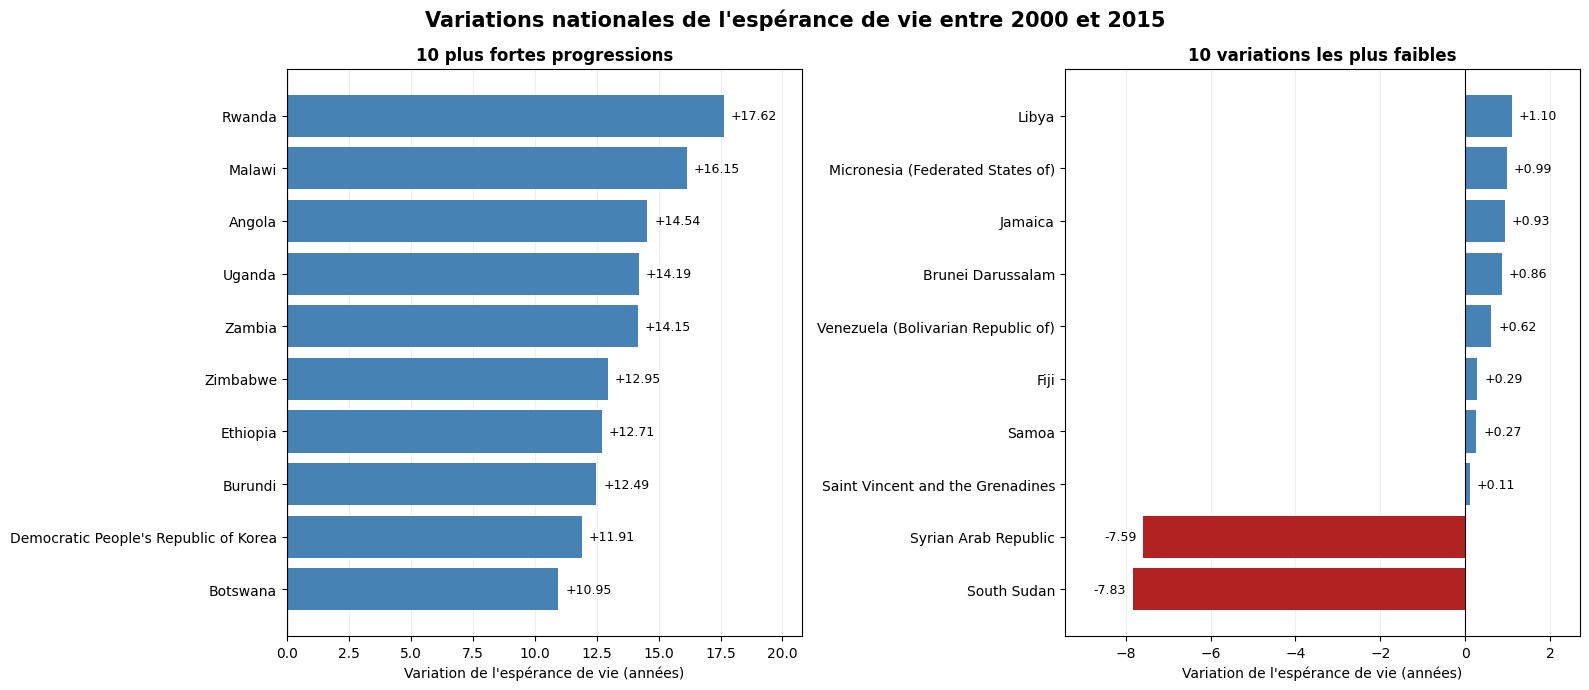

In [8]:

# Préparer les données pour les graphiques
top_plot = top_progressions.sort_values("variation")
bottom_plot = bottom_progressions.sort_values("variation")

# Créer deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Graphique 1 : plus fortes progressions
axes[0].barh(
    top_plot.index,
    top_plot["variation"],
    color="steelblue"
)

axes[0].set_title("10 plus fortes progressions", fontweight="bold")
axes[0].set_xlabel("Variation de l'espérance de vie (années)")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].grid(axis="x", alpha=0.2)
axes[0].set_axisbelow(True)

# Graphique 2 : variations les plus faibles
couleurs = [
    "firebrick" if valeur < 0 else "steelblue"
    for valeur in bottom_plot["variation"]
]

axes[1].barh(
    bottom_plot.index,
    bottom_plot["variation"],
    color=couleurs
)

axes[1].set_title("10 variations les plus faibles", fontweight="bold")
axes[1].set_xlabel("Variation de l'espérance de vie (années)")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].grid(axis="x", alpha=0.2)
axes[1].set_axisbelow(True)

# Ajouter les valeurs sur les barres
for ax, donnees in zip(axes, [top_plot, bottom_plot]):
    for i, valeur in enumerate(donnees["variation"]):
        ax.annotate(
            f"{valeur:+.2f}",
            xy=(valeur, i),
            xytext=(5 if valeur >= 0 else -5, 0),
            textcoords="offset points",
            ha="left" if valeur >= 0 else "right",
            va="center",
            fontsize=9
        )
    ax.margins(x=0.18)

fig.suptitle(
    "Variations nationales de l'espérance de vie entre 2000 et 2015",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Constat :** Les diagrammes mettent en évidence des différences importantes dans l'évolution de l'espérance de vie entre 2000 et 2015.

Les dix pays ayant enregistré les progressions les plus élevées présentent des gains compris entre 10,95 et 17,62 ans. Le Rwanda occupe la première position, suivi du Malawi et de l'Angola.

À l'inverse, le Soudan du Sud et la Syrie sont les seuls pays du panel ayant enregistré une diminution, respectivement de 7,83 et de 7,59 ans. Les huit autres pays figurant parmi les variations les plus faibles présentent des progressions positives, mais inférieures à 1,10 an.

Ces résultats illustrent le caractère hétérogène de l'évolution de l'espérance de vie entre les pays.

Les progressions particulièrement importantes observées dans plusieurs pays initialement caractérisés par une faible espérance de vie contribuent à expliquer le rapprochement global des niveaux nationaux.

Toutefois, les reculs du Soudan du Sud et de la Syrie montrent que cette amélioration n'est pas universelle.

Ces variations correspondent aux différences entre les valeurs de 2000 et de 2015. Elles ne permettent pas de déterminer si les évolutions ont été régulières durant les années intermédiaires.

### 5.4.4 Examen des trajectoires nationales

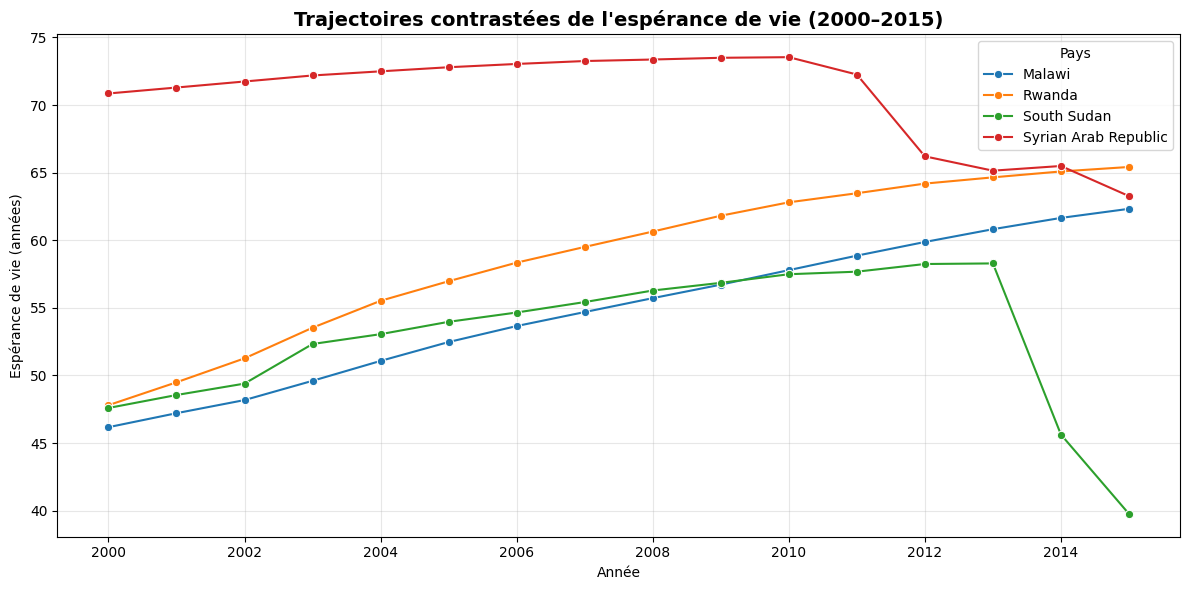

In [9]:

# Sélectionner quatre pays aux évolutions contrastées
pays_selectionnes = [
    "Rwanda",
    "Malawi",
    "South Sudan",
    "Syrian Arab Republic"
]

# Filtrer les observations de ces pays
trajectoires = df_panel[
    df_panel["country"].isin(pays_selectionnes)
].copy()

# Visualiser l'évolution annuelle
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=trajectoires,
    x="year",
    y="life_expectancy",
    hue="country",
    marker="o"
)

plt.title(
    "Trajectoires contrastées de l'espérance de vie (2000–2015)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Année")
plt.ylabel("Espérance de vie (années)")
plt.xticks(range(2000, 2016, 2))
plt.grid(alpha=0.3)
plt.legend(title="Pays")
plt.tight_layout()
plt.show()



**Constat :** L'examen des trajectoires annuelles de quatre pays révèle des évolutions différentes entre 2000 et 2015.

Le Rwanda et le Malawi enregistrent des progressions continues de leur espérance de vie, avec des gains respectifs de 17,62 et 16,15 ans. Leurs courbes montrent une amélioration relativement régulière sur l'ensemble de la période, malgré des variations dans le rythme de progression.

À l'inverse, la Syrie et le Soudan du Sud présentent des ruptures importantes après plusieurs années d'amélioration.

En Syrie, l'espérance de vie progresse jusqu'aux alentours de 2010, avant de diminuer fortement à partir de 2011. Au Soudan du Sud, la progression se poursuit jusqu'en 2013, puis laisse place à une chute particulièrement marquée en 2014 et 2015.

Ces trajectoires montrent que les variations calculées entre 2000 et 2015 ne décrivent pas nécessairement l'évolution réelle d'un pays pendant l'ensemble de la période.

Une variation négative peut résulter d'une rupture importante survenue après plusieurs années de progression, comme l'illustrent la Syrie et le Soudan du Sud.

À l'inverse, les trajectoires du Rwanda et du Malawi montrent que certaines progressions importantes se construisent de manière relativement continue.

Ces observations soulignent l'intérêt d'associer les comparaisons entre deux années à une analyse des séries temporelles complètes. Les causes des ruptures identifiées nécessiteraient toutefois des données complémentaires et une analyse spécifique.

## 5. Analyse statistique pour la comparaison appariée 2000–2015

### 5.1. Objectif et hypothèses statistiques

L'analyse descriptive précédente a montré une progression de l'espérance de vie moyenne entre 2000 et 2015 sur le panel équilibré de 183 pays.

Cette analyse statistique vise à déterminer si la variation moyenne observée entre ces deux années est statistiquement significative.

**Question statistique :** L'espérance de vie moyenne des 183 pays a-t-elle significativement changé entre 2000 et 2015 ?

**Hypothèses :**

- **H₀ :** la moyenne des différences d'espérance de vie entre 2015 et 2000 est nulle (μd = 0).
- **H₁ :** la moyenne des différences d'espérance de vie entre 2015 et 2000 est différente de zéro (μd ≠ 0).

**Test retenu :** Test t de Student pour échantillons appariés, avec un seuil de significativité de 5 % (α = 0,05).

Le test apparié est approprié parce que chaque pays dispose de deux observations liées : une en 2000 et une en 2015.

Il permet de déterminer si la moyenne des variations nationales est statistiquement différente de zéro, en tenant compte de cet appariement.

Les conditions d'application seront examinées en particulier à partir de la distribution des différences entre les deux années.

In [ ]:
# Réalisation du test
from scipy.stats import ttest_rel, shapiro

# Conserver les pays avec les deux valeurs disponibles
donnees_test = evolution_pays[
    ["esperance_2000", "esperance_2015", "variation"]
].dropna().copy()

# Examiner les différences appariées
differences = donnees_test["variation"]

print("Nombre de pays :", len(donnees_test))
print(f"Variation moyenne : {differences.mean():.2f} ans")
print(f"Variation médiane : {differences.median():.2f} ans")
print(f"Écart-type des différences : {differences.std():.2f} ans")

# Vérifier la normalité des différences avec Shapiro-Wilk
stat_shapiro, p_shapiro = shapiro(differences)

print("\nTest de normalité de Shapiro-Wilk")
print(f"Statistique W : {stat_shapiro:.4f}")
print(f"p-value : {p_shapiro:.4g}")

# Réaliser le test t apparié (2015 - 2000)
t_stat, p_value = ttest_rel(
    donnees_test["esperance_2015"],
    donnees_test["esperance_2000"]
)

print("\nTest t apparié")
print(f"Statistique t : {t_stat:.4f}")
print(f"p-value : {p_value:.4g}")
print("Degrés de liberté :", len(donnees_test) - 1)
print("Seuil de significativité : 0.05")


Nombre de pays : 183
Variation moyenne : 4.80 ans
Variation médiane : 4.31 ans
Écart-type des différences : 3.33 ans

Test de normalité de Shapiro-Wilk
Statistique W : 0.9026
p-value : 1.306e-09

Test t apparié
Statistique t : 19.4890
p-value : 2.034e-46
Degrés de liberté : 182
Seuil de significativité : 0.05


### 5.3. Résultats et interprétation du test t apparié

**Résultats des tests :**

- Nombre de pays : 183.
- Variation moyenne : +4,80 ans.
- Variation médiane : +4,31 ans.
- Écart-type des différences : 3,33 ans.
- Test de Shapiro-Wilk : W = 0,9026 ; p = 1,306 × 10⁻⁹.
- Test t apparié : t(182) = 19,4890 ; p = 2,034 × 10⁻⁴⁶.
- Seuil de significativité : α = 0,05.

**Constat :** Le test de Shapiro-Wilk met en évidence un écart statistiquement significatif à la normalité des variations nationales entre 2000 et 2015.

Le test t apparié révèle néanmoins une variation moyenne statistiquement significative de l'espérance de vie entre les deux années (p < 0,05). L'hypothèse nulle d'une variation moyenne égale à zéro est donc rejetée.

Les résultats confirment une augmentation moyenne de l'espérance de vie de 4,80 ans dans le panel des 183 pays étudiés.

**Conclusion statistique :** Les données mettent en évidence une augmentation moyenne statistiquement significative de l'espérance de vie entre 2000 et 2015. Cette conclusion complète les analyses descriptives, tout en soulignant la diversité des trajectoires nationales.

## 6. Synthèse des résultats et conclusion

### 6.1. Principaux résultats

L'analyse de l'évolution de l'espérance de vie entre 2000 et 2015, réalisée sur un panel équilibré de 183 pays, met en évidence quatre principaux constats.

**Premièrement, l'espérance de vie a globalement progressé au cours de la période étudiée.** La moyenne des 183 pays passe de 66,40 ans en 2000 à 71,20 ans en 2015, soit une augmentation de 4,80 ans. La médiane progresse également, passant de 69,58 à 72,82 ans, ce qui confirme une amélioration des niveaux centraux de la distribution.

**Deuxièmement, la dispersion globale entre les pays a diminué, malgré la persistance de disparités importantes.** L'écart-type passe de 9,75 ans en 2000 à 8,26 ans en 2015, suggérant un rapprochement des niveaux nationaux d'espérance de vie.

Toutefois, l'étendue augmente de 36,25 à 44,03 ans entre les deux années de référence. Elle présente également des pics importants en 2009 et en 2011, associés à des valeurs minimales particulièrement faibles. Ces résultats montrent que la réduction de la dispersion globale peut coexister avec des écarts importants entre les situations extrêmes.

**Troisièmement, l'amélioration concerne la très grande majorité des pays, mais son ampleur varie considérablement.** Parmi les 183 pays étudiés, 181 enregistrent une progression de leur espérance de vie entre 2000 et 2015, soit 98,91 % du panel.

La variation moyenne atteint +4,80 ans, avec des gains particulièrement importants au Rwanda (+17,62 ans), au Malawi (+16,15 ans) et en Angola (+14,54 ans).

À l'inverse, seuls deux pays présentent un recul entre les années de référence : le Soudan du Sud (−7,83 ans) et la Syrie (−7,59 ans).

**Quatrièmement, les trajectoires nationales révèlent des évolutions contrastées.** L'examen des séries annuelles montre que les progressions du Rwanda et du Malawi sont relativement continues sur la période étudiée.

En revanche, la Syrie et le Soudan du Sud présentent des ruptures importantes après plusieurs années d'amélioration. Leurs variations négatives entre 2000 et 2015 ne traduisent donc pas une diminution régulière sur l'ensemble de la période.

### 6.2. Réponse à la question analytique

Entre 2000 et 2015, l'espérance de vie a globalement augmenté dans les 183 pays du panel équilibré, avec une progression moyenne de 4,80 ans.

Cette amélioration s'accompagne d'une diminution de la dispersion globale des niveaux d'espérance de vie entre les pays, ce qui suggère un certain rapprochement des situations nationales.

Toutefois, cette évolution n'est pas uniforme. Les gains varient considérablement d'un pays à l'autre, tandis que certaines trajectoires présentent des ruptures importantes ou des reculs.

Ainsi, **l'évolution de l'espérance de vie entre 2000 et 2015 se caractérise par une amélioration largement partagée, mais inégale dans son ampleur et dans sa dynamique temporelle**.

### 6.3. Limites de l'analyse

Plusieurs limites méthodologiques doivent être prises en considération.

**Couverture géographique :** L'analyse repose sur un panel équilibré de 183 pays afin de garantir la comparabilité temporelle. Les dix autres pays du jeu de données initial sont exclus en raison de leur couverture incomplète.

**Méthode de calcul :** Les moyennes annuelles sont calculées sans pondération par la population. Les résultats décrivent donc l'évolution moyenne des pays étudiés et non celle de l'espérance de vie mondiale pondérée par le nombre d'habitants.

**Sensibilité aux valeurs atypiques :** Certaines observations présentent des valeurs exceptionnellement faibles, notamment en République centrafricaine en 2009, en Somalie en 2011 et au Soudan du Sud en 2015. Ces valeurs peuvent influencer les indicateurs de dispersion et nécessitent une certaine prudence dans l'interprétation des évolutions.

**Analyse des variations nationales :** Les classements des progressions et des reculs reposent sur les différences entre 2000 et 2015. Ces variations ne résument pas nécessairement les fluctuations observées durant les années intermédiaires.

**Portée explicative :** L'analyse est descriptive. Elle permet d'identifier les tendances, les disparités et les ruptures temporelles, mais ne permet pas d'en déterminer les causes sanitaires, économiques, politiques ou sociales.

### 6.4. Conclusion

Cette User Story a permis d'étudier l'évolution temporelle de l'espérance de vie entre 2000 et 2015, en combinant l'analyse des tendances globales, la mesure des disparités et l'examen des trajectoires nationales.

Les résultats montrent une progression générale de l'espérance de vie dans la quasi-totalité des pays étudiés, accompagnée d'une réduction de la dispersion globale.

Ils soulignent néanmoins que les améliorations ne sont pas uniformes et que certaines situations nationales restent particulièrement défavorables ou marquées par des ruptures importantes.

Cette analyse complète les résultats des User Stories précédentes : LEP-14, consacrée à l'identification des pays situés aux extrêmes de la distribution, et LEP-15, portant sur les différences selon le statut de développement.

Ensemble, ces trois analyses constituent une première caractérisation descriptive des disparités internationales d'espérance de vie, de leur répartition et de leur évolution entre 2000 et 2015.

Elles fournissent ainsi une base pour les prochaines étapes du projet, consacrées à l'étude des facteurs sanitaires, socioéconomiques et démographiques susceptibles d'être associés aux différences d'espérance de vie observées.